# 15 模糊数学的基本概念和基本运算

> **模块**：模糊数学 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、scikit-fuzzy

## 1. 问题背景

模糊数学是研究和揭示模糊现象的定量处理方法。模糊性数学发展的主流是在它的应用方面。由于模糊性概念已经找到了模糊集的描述方式，人们运用概念进行判断、评价、推理、决策和控制的过程也可以用模糊性数学的方法来描述。例如模糊聚类分析、模糊模式识别、模糊综合评判、模糊决策与模糊预测、模糊控制、模糊信息处理等。


## 2. 学习目标

- 掌握模糊数学基本概念
- 掌握模糊数学的基本运算


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 模糊数学基本概念

在人类社会和各个科学领域中，人们所遇到的各种量大体上可以分成两大类：确定性的与不确定性的，而不确定性又可分为随机性和模糊性。人们正是用三种数学来分别研究客观世界中不同的量，即：

- 第一类是确定性数学模型。这类模型研究的对象具有确定性，对象之间具有必然的关系，最典型的就是用微分法、微分方程、差分方程所建立的数学模型。
- 第二类是随机性数学模型。这类模型研究的对象具有随机性，对象之间具有偶然的关系，如用概率分布方法、马尔可夫 (Markov) 链所建立的数学模型。
- 第三类是模糊性数学模型。这类模型所研究的对象与对象之间的关系具有模糊性。

#### 4.1.1 模糊集和隶属函数

无论是概率论还是模糊数学，其基础都是从集合开始，概率论建立在经典集合之上，而模糊数学则以模糊集合为基础。

##### 4.1.1.1 特征函数

对于一个经典集合 A，其特征函数表示为：

$$
\mathcal{X}_A(x) = \begin{cases}1, & x∈A \\0, & x∉A \end{cases}

$$

即对于一个元素 x，如果属于集合 A，特征函数值为 1，否则为 0。集合 A 由特征函数唯一确定。

> *原稿配图未随 notebook 保存，此处暂缺。*

##### 4.1.1.2 隶属函数

**论域**：被讨论的对象（元素）的全体称为论域。与集合一样，通常用大写字母 U, V 等表示，从某种方面来说，论域与经典集合中全集是相对应的，只不过经典集合中，全集中的元素绝对属于或不属于经典集合 A，A 是全集的子集；而模糊集合中，论域中所有元素是不同程度地属于模糊集 A，无法绝对刻画，A 是论域的模糊子集。

在模糊数学中，称没有明确边界（没有清晰外延）的集合为模糊集合。常用大写字母来表示。元素属于模糊集合的程度用隶属度来表示。用于计算隶属度的函数称为隶属函数。

**定义 1**：设 U 是论域，论域 U 到 [0,1] 闭区间上的任意映射

$$
M: U \rightarrow [0,1]

$$

$$
u \mapsto M(u) ∈ [0,1]

$$

确定了 U 上的一个模糊子集，映射 M(u) 叫做 M 的隶属函数，或称为 u 对 M 的隶属度。

> *原稿配图未随 notebook 保存，此处暂缺。*

例如上图的模糊子集 $A$：
- 若 $u$ 位于 $A$ 的内部，则用 1 来记录。
- 若 $u$ 位于 $A$ 的外部，则用 0 来记录。
- 若 $u$ 一部分位于 $A$ 的内部，一部分位于 $A$ 的外部，则用 $u$ 位于 $A$ 内部的长度来表示 $u$ 对于 $A$ 的隶属度。
- $M(u)$ 越接近于 0，表示 $u$ 隶属于 $M$ 的程度越小；
- $M(u)$ 越接近于 1，表示 $u$ 隶属于 $M$ 的程度越大；
- **$M(u) = 0.5$，称为模糊集的过渡点，此点最具有模糊性。**

常用的隶属函数有很多种，以三角形隶属函数和梯形隶属函数为例，自定义函数并绘制图像。

1. 三角形隶属函数曲线的形状由三个参数 $a$，$b$，$c$ 确定：

$$
f(x, a, b, c) =
\begin{cases}
0, & x \leq a \\
\frac{x - a}{b - a}, & a < x \leq b \\
\frac{c - x}{c - b}, & b < x \leq c \\
0, & x > c
\end{cases}

$$


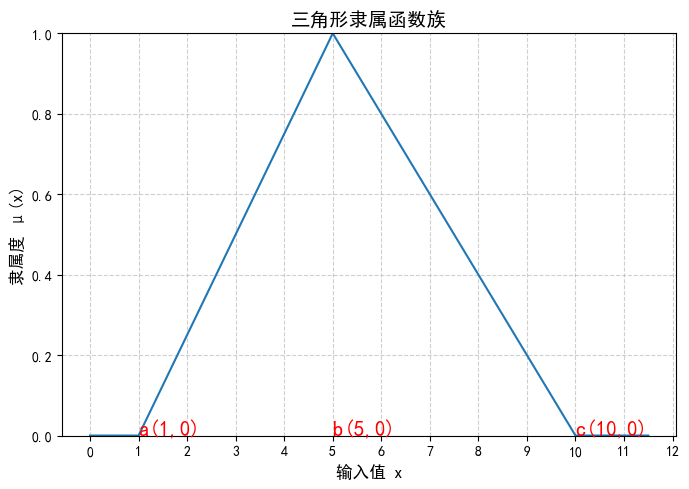

In [4]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rc('axes', unicode_minus=False)

def triangular(x, a, b, c):
    return np.piecewise(x, [x <= a, (a < x) & (x <= b), (b < x) & (x < c), x >= c],
                        [0, lambda x: (x-a)/(b-a), lambda x: (c-x)/(c-b), 0])

x = np.arange(0, 12, 0.5)
a, b, c = 1, 5, 10
y = triangular(x, a, b, c)

plt.figure(figsize=(7,5))
plt.plot(x, y)
plt.xticks(range(13))
plt.ylim(0, 1)
plt.xlabel('输入值 x', fontsize=12)
plt.ylabel('隶属度 μ(x)', fontsize=12)
plt.title('三角形隶属函数族', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
for val, label in zip([a, b, c], [f'a({a},0)', f'b({b},0)', f'c({c},0)']):
    plt.text(val, 0, label, fontsize=15, color='r')
plt.tight_layout()
plt.show()

2. 梯形隶属函数曲线的形状由四个参数 a，b，c，d 确定：

$$
f(x,a,b,c,d) =
\begin{cases}
0, & \quad x \leq a \\
\frac{x-a}{b-a}, & \quad a < x \leq b \\
1, & \quad b < x \leq c \\
\frac{d-x}{d-c}, & \quad c < x \leq d \\
0, & \quad x > d
\end{cases}

$$

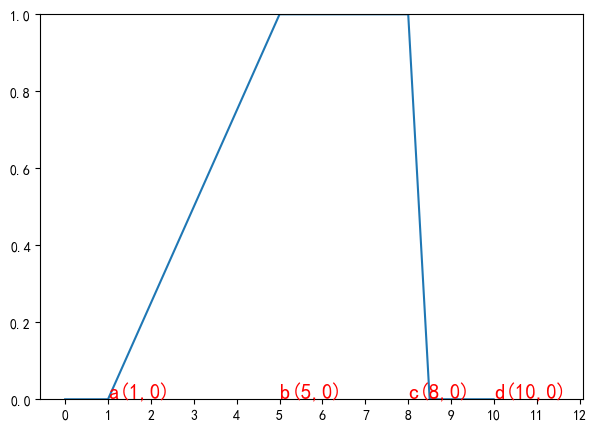

In [5]:
# 自定义梯形隶属函数
def trapezoid(x, a, b, c, d):
    return np.piecewise(x, 
                        [x <= a, (a < x) & (x <= b), (b < x) & (x <= c), x > d],
                        [0, lambda x: (x-a)/(b-a), 1, lambda x: (d-x)/(d-c)])

x = np.arange(0, 12, 0.5)
y = trapezoid(x, 1, 5, 8, 10)

plt.figure(figsize=(7,5))
plt.plot(x, y)
plt.xticks(range(13))
plt.ylim(0, 1)
# 使用for循环得到隶属函数的值
for pos, label in zip([1,5,8,10], ['a(1,0)','b(5,0)','c(8,0)','d(10,0)']):
    plt.text(pos, 0, label, fontsize=15, color='r')
plt.show()

#### 4.1.2 模糊集的表示

模糊子集通常简称模糊集，其表示方法有：
- 扎德表示法
$M=\sum_{i=1}^{n}{\frac{M(u_i)}{u_i}} =\frac{M(u_1)}{u_1}+\frac{M(u_2)}{u_2}+...+\frac{M(u_n)}{u_n} $
这里$\frac{M(u_i)}{u_i}$表示$u_i$对模糊集$M$的隶属度是$M(u_i)$

- 序偶表示法
$M = \{(u_1,M(u_1)),(u_2,M(u_2)),...,(u_n,M(u_n))\}$

- 向量表示法
$M = (M(u_1),M(u_2),...,M(u_n))$

若论域$U$为无限集，其上的模糊集$M$表示为
$M =\int_{u∈M}{\frac{M(u)}{u}}$

### 4.2 模糊数学的基本运算

#### 4.2.1 模糊集的运算

设$A,B$为论域$U$上的两个模糊集合，则$A与B$的并集$A∪B$、交集$A∩B$、补集$ \overline{A}$也是论域上的模糊集合，其定义如下：
- 并集：
$A∪B = \{(u,A∪B(u))|A∪B(u) = max\{A(u),B(u)\}, u∈U\}$

- 交集：
$A∩B = \{(u,A∩B(u))|A∩B(u) = min\{A(u),B(u)\}, u∈U\}$

- 补集：
$\overline{A} = \{(u,\overline{A}(u))| \overline{A}(u) = 1-A(u), u∈U\}$

**例1**. 设$A = \{(u_1,0.3),(u_2,0.9),(u_3,1.0),(u_4,0.8),(u_5,0.5)\}, B = \{(u_1,0.2),(u_2,0.1),(u_3,0.8),(u_4,0.3),(u_5,0.6)\}$，求$A∪B$、$A∩B$和$ \overline{A}$。

这里，我们使用skfuzzy库来进行计算。skfuzzy是一个用于SciPy的模糊逻辑工具箱。

- 计算两个模糊集的交集
`skfuzzy.fuzzy_and(x, mfx, y, mfy)`

- 计算两个模糊集的并集
`skfuzzy.fuzzy_or(x, mfx, y, mfy)`

- 计算模糊集的补集
`skfuzzy.fuzzy_not(mfx)`

- 其中：
- `x` : 模糊隶属函数的全域变量
- `mfx` : 全域变量$x$的模糊隶属函数
- `y` : 模糊隶属函数的全域变量
- `mfy` : 全域变量$y$的模糊隶属函数

In [7]:
import numpy as np
from skfuzzy import fuzzy_and, fuzzy_or, fuzzy_not
x = np.arange(1, 6)
A = np.array([0.3, 0.9, 1, 0.8, 0.5])
B = np.array([0.2, 0.1, 0.8, 0.3, 0.6])

print('模糊集A和B的交集为:', fuzzy_and(x, A, x, B), '\n模糊集A和B的并集为:', fuzzy_or(x, A, x, B), '\n模糊集A的补集为:', fuzzy_not(A), '\n模糊集B的补集为:', fuzzy_not(B))

模糊集A和B的交集为: (array([1, 2, 3, 4, 5]), array([0.2, 0.1, 0.8, 0.3, 0.5])) 
模糊集A和B的并集为: (array([1, 2, 3, 4, 5]), array([0.3, 0.9, 1. , 0.8, 0.6])) 
模糊集A的补集为: [0.7 0.1 0.  0.2 0.5] 
模糊集B的补集为: [0.8 0.9 0.2 0.7 0.4]


**注意：skfuzzy库模糊子集的元素只支持数字。**

#### 4.2.2 模糊关系及运算

##### 4.2.2.1 关系与模糊关系

关系是指对两个普通集合的直积施加某种条件限制后得到的序偶集合，常用R表示。

**例2**.设$A=\{1,3,5\},B=\{2,4,6\}$（向量表示法），则其积集合为：

$$A×B = \{(1,2),(1,4),(1,6),(3,2),(3,4),(3,6),(5,2),(5,4),(5,6)\}$$
对$A×B$施加$a＞b(a∈A,b∈B)$的条件限制后得到的新的集合定义为关系，记作$R_{a＞b}$，则

$$R_{a＞b} \quad= \{(3,2),(5,2),(5,4)\}$$

矩阵形式表示为：

$$R_{a＞b} \quad=\quad
\begin{bmatrix}
0 & 0 &0 \\
1 & 0 &0 \\
1 & 1 &0
\end{bmatrix}

$$

模糊关系指对普通集合的直积施加某种模糊条件限制后得到的模糊关系，也记作R。

##### 4.2.2.2 模糊关系矩阵的运算

设$R={(r_{ij})}_{m×n}$，$S={(s_{ij})}_{m×n}$为同一论域U上的两个模糊关系矩阵，$i = 1,2,...m,j=1,2,...,n$则其并、交、补运算分别定义为：
- 并运算：$T = R∪S = {(t_{ij})}_{m×n},t_{ij} = max(r_{ij},s_{ij})\triangleq(r_{ij}∨s_{ij})；$
- 交运算：$T = R∩S = {(t_{ij})}_{m×n},t_{ij} = min(r_{ij},s_{ij})\triangleq(r_{ij}∧s_{ij})；$
- 补运算：$T = \overline{R} = {(t_{ij})}_{m×n},t_{ij} = 1-r_{ij}。$

设模糊关系矩阵$R={(r_{ij})}_{m×n}$，$S={(s_{ij})}_{n×l}$，则$R$对$S$的合成运算：$T ={(t_{ik})}_{m×l}\quad,t_{ik} = ∨_{j=1}^{n} (r_{ij}∧s_{ij})$，记作$T=R∘S$

**例3**.设$R=[0.3,0.35,0.1]$，$S=\begin{bmatrix}
0.3 & 0.5 &0.2 \\
0.2 & 0.2 &0.4 \\
0.3 & 0.4 &0.2
\end{bmatrix}$，计算$T=R∘S$。

In [8]:
R = np.array([0.3,0.35,0.1])
print('复制前数组形状：',R.shape)
# np.tile() 数组复制
RR = np.tile(R,(len(R),1)) 
print('复制后数组形状：',RR.shape)
S = np.array([[0.3,0.5,0.2],[0.2,0.2,0.4],[0.3,0.4,0.2]])
# 先比较元素最小值再比较整体最大值

# np.minimum()取对应位置上的小值
# 两个矩阵的元素对应取最小值
# 因为是每行和每列元素对应最小值，所以RR矩阵转置
c = np.minimum(RR.T,S)  
# 再比较每列的最大值
T = c.max(axis=0)   
print("T=",T)

复制前数组形状： (3,)
复制后数组形状： (3, 3)
T= [0.3  0.3  0.35]


### 4.3 模糊综合评判

> 来源：教材参考实现《数学建模算法与应用》14.2 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

1. 一级模糊综合评判(375页)
    1. 确定因素集 U = {u_1, u_2, ..., u_n}
    2. 确定评语集 V = {v_1, v_2, ..., v_m}. 如优秀, 良好, 一般, 较差, 差.
    3. 确定各因素权重 A = [a_1, a_2, ..., a_n]. 一般方法有: Delphi法, 加权平均法, 众人评估法等
    4. 确定模糊综合评判矩阵 R
    5. 评判结果: B=A·R
2. 多层次模糊综合评判

In [ ]:
# 一级模糊综合评判
# U = ['政治表现', '工作能力', '工作态度', '工作成绩']
# V = ['优秀', '良好', '一般', '较差', '差']
# A = [0.25, 0.2, 0.25, 0.3]
# 群众打分中, 分别有 10%, 50%, 40%, 0%, 0% 的人认为政治表现 优秀, 良好, 一般, 较差, 差
# 因此, R[0] = [0.1, 0.5, 0.4, 0., 0.]
# 以此类推.

import numpy as np

V = ['优秀', '良好', '一般', '较差', '差']
# 权重
A = [0.25, 0.2, 0.25, 0.3]
# 模糊综合评判矩阵
R = [[0.1, 0.5, 0.4, 0.0, 0.0],
     [0.2, 0.5, 0.2, 0.1, 0.0],
     [0.2, 0.5, 0.3, 0.0, 0.0],
     [0.2, 0.6, 0.2, 0.0, 0.0]]
B = np.matmul(A, R)
print('综合评语为: ', B)
print('按照选取数值最大的原则, 得到最终评判结果为: ', V[np.argmax(B)])

In [ ]:
# 多层次模糊综合评判
# 一级指标权重: 
A = [0.4, 0.3, 0.2, 0.1]
# 二级指标权重: 
AA = [[0.2, 0.3, 0.3, 0.2],
      [0.3, 0.2, 0.1, 0.2, 0.2],
      [0.1, 0.2, 0.3, 0.2, 0.2],
      [0.3, 0.2, 0.2, 0.3]]

# 获取每一小项的评语
R = np.loadtxt('../data/textbook/14.D 多层次模糊综合评判数据.txt') 
R1 = R[:4]
R2 = R[4:9]
R3 = R[9:14]
R4 = R[14:]

# 计算每一大项的评语
R = np.array([np.matmul(AA[0], R1), 
              np.matmul(AA[1], R2),
              np.matmul(AA[2], R3),
              np.matmul(AA[3], R4)])
B = np.matmul(A, R)
print('综合评语为: ', B)
print('按照选取数值最大的原则, 得到最终评判结果为: ', V[np.argmax(B)])

## 5. 小结

本次实验介绍了模糊数学基本概念和模糊数学的基本运算，基于skfuzzy和numpy实现了模糊集的运算和模糊关系矩阵的运算。

通过本次实验需要掌握以下内容：
- 掌握模糊数学基本概念
- 掌握模糊数学的基本运算